# Linear Regression

This notebook will attempt to use basic Linear Regression and more advanced Polynomial Regression models on the prepared csv data.

I will be exploring the relationship of Material Difference of a given position to its Evaluation. Given a material only evaluation of Stockfish, we may expect that 1 point of material difference would equal to 1 point of evaluation. This, however, is not the case as you will see below.

First, import the CSV:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

print("Imports successful")
csv = pd.read_csv('chessData_formatted.csv')
print("Read CSV successful")

Imports successful
Read CSV successful


### Prepare graph function

This function will set up the graph.

In [2]:
def prepare_graph(x_axis, y_axis, title):
    plt.figure(figsize=[7,4])
    plt.scatter(x_axis,y_axis)
    plt.axhline(y=158, color=(0.1, 0.1, 0.5), linestyle='-')
    plt.xlabel('Material Difference')
    plt.ylabel('Average Evaluation')
    plt.title(title)
    plt.xlim(0)
    plt.ylim(0)

### Basic graph

The data has been prepared further, with negative values (i.e. black player) being flipped and normalized with positive white player values. Each point represents the average evaluation given the material difference.

A blue line is present on every graph, any point above this line denotes a Mate position, where a Checkmate is inevitable.

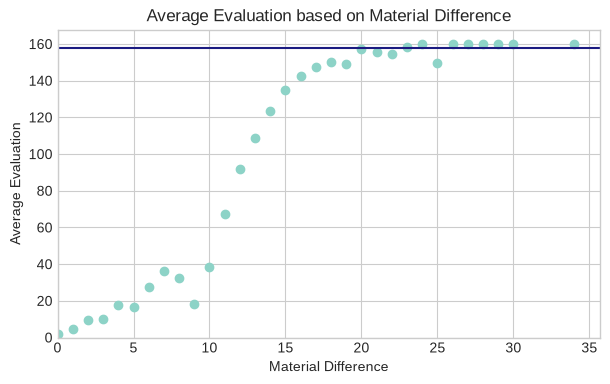

In [3]:
materialDiff = np.abs(csv['material_diff'])
evaluations = np.abs(csv['Evaluation']) / 100

df = pd.DataFrame({
    'materialDiff': materialDiff,
    'evaluations': evaluations
})
grouped = df.groupby('materialDiff')['evaluations'].mean()

x = grouped.index
y = grouped.values

xnumpy = x.to_numpy()

prepare_graph(x, y, 'Average Evaluation based on Material Difference')
plt.show()

### Prepare model function

Helper function to prepare and plot the regression functions below

In [4]:
def prepare_model(model):
    model.fit(xnumpy[:, np.newaxis], y)
    xfit = np.linspace(0, x.max())
    yfit = model.predict(xfit[:, np.newaxis])
    plt.plot(xfit, yfit)

## Linear Regression

A basic Linear Regression has been performed on the data above, however as you can see the best fit model is not very accurate due to the non-linear data.

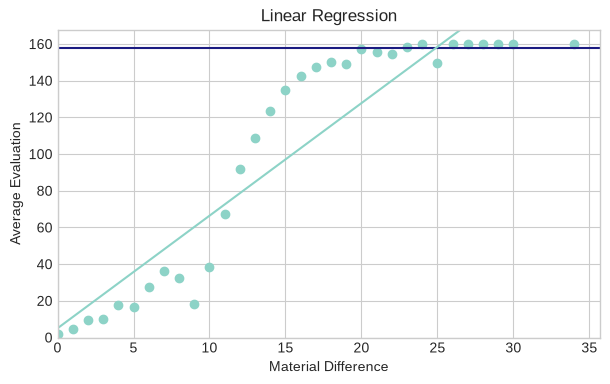

In [5]:
from sklearn.linear_model import LinearRegression

model = LinearRegression(fit_intercept=True)
prepare_graph(x, y, 'Linear Regression')
prepare_model(model)
plt.show()

## Polynomial Regression

A polynomial regression has been performed on the data. This model gives a much better fit to the dataset but can be improved further with better models.

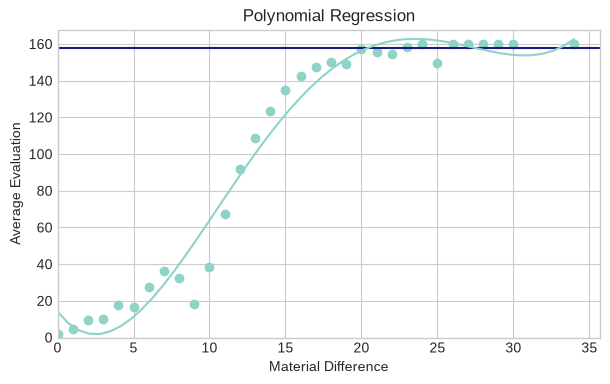

In [6]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

poly_model = make_pipeline(PolynomialFeatures(4), LinearRegression())
prepare_graph(x,y, 'Polynomial Regression')
prepare_model(poly_model)
plt.show()

### Gaussian Basis Functions

A standard polynomial basis function is limited. A Gaussian Basis Function is a different method of estimating the data for regression models.

In [7]:
from sklearn.base import BaseEstimator, TransformerMixin

class GaussianFeatures(BaseEstimator, TransformerMixin):
    """Uniformly spaced Gaussian features for one-dimensional input"""

    def __init__(self, N, width_factor=2.0):
        self.N = N
        self.width_factor = width_factor

    @staticmethod
    def _gauss_basis(x, y, width, axis=None):
        arg = (x - y) / width
        return np.exp(-0.5 * np.sum(arg ** 2, axis))

    def fit(self, X, y=None):
        # create N centers spread along the data range
        self.centers_ = np.linspace(X.min(), X.max(), self.N)
        self.width_ = self.width_factor * (self.centers_[1] - self.centers_[0])
        return self

    def transform(self, X):
        return self._gauss_basis(X[:, :, np.newaxis], self.centers_,
                                 self.width_, axis=1)

### Display basis plot

This helper function sets up and displays the basis plot graph that the model used.

In [8]:
def display_basis_plot(model):
    plt.figure(figsize=[7,2])
    plt.plot(model.steps[0][1].centers_,model.steps[1][1].coef_)
    plt.xlabel('Basis Location')
    plt.ylabel('Coefficient')
    plt.title('Basis Plot')
    plt.xlim(0)
    plt.show()

## Ridge Regression

Ridge regression is a form of L2 regularization. Regularization functions prevent overfitting of models by applying different penalties and math functions.

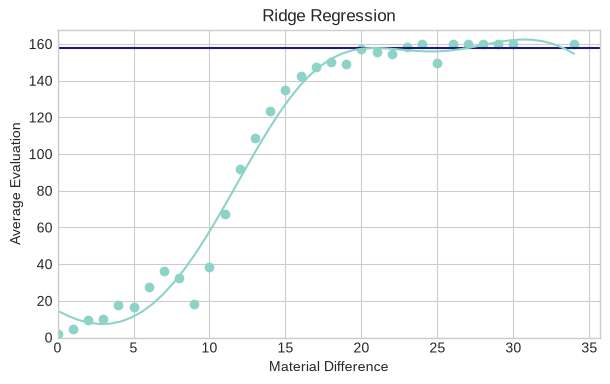

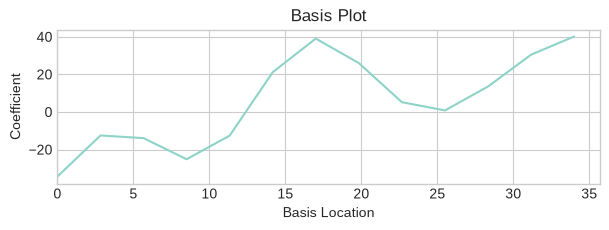

In [9]:
from sklearn.linear_model import Ridge
ridge_model = make_pipeline(GaussianFeatures(13), Ridge(alpha=0.1))
prepare_graph(x, y, 'Ridge Regression')
prepare_model(ridge_model)
plt.show()
display_basis_plot(ridge_model)

## Lasso Regression

Lasso regression is a form of L1 regularization. Like Ridge Regression above, this is another way to regularize the model to prevent overfitting.

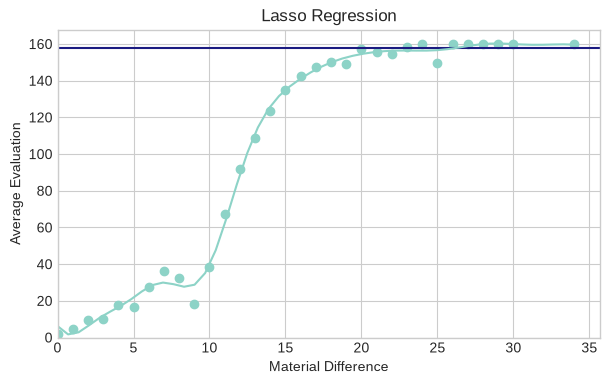

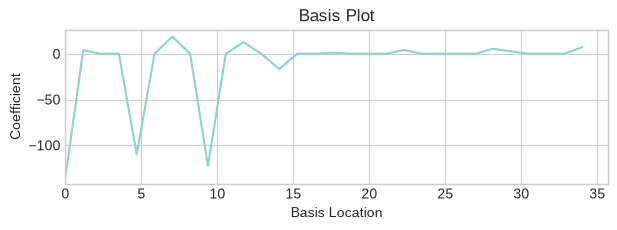

In [10]:
from sklearn.linear_model import Lasso
lasso_model = make_pipeline(GaussianFeatures(30), Lasso(alpha=0.01, max_iter=2000))
prepare_graph(x, y, 'Lasso Regression')
prepare_model(lasso_model)
plt.show()
display_basis_plot(lasso_model)

## Conclusion

The Lasso Regression model seems to be the best model for displaying a Linear Regression of the data without overfitting.

### Results:
- Games with a material difference 9 or less (i.e. queen or lesser piece) seem to be more evenly evaluated. Most chess games fall within this category.
- Material difference of more than 9 show that the chances of winning rise rapidly with each point of extra material, with the majority of games evaluating to a forced checkmate after roughly 20 points of material difference. This aligns well with highly unbalanced games being easy to win.
- If material difference correlated equally to the evaluation, we would have a 1:1 45 degree slope graph. However, just because a player may be up 3 points of material, does not mean that their advantage is 3 points. In the majority of games, that player would also have a tactical and positional advantage further boosting the evaluation.
- Some positions can be losing, even if the material difference is winning for that player. This represents the minority of positions, and had no meaningful impact on the data.
- The dip at Material Difference 9 is interesting, as that could mean that there's a sizeable portion of positions where having a queen advantage in material does not necessarily mean the positon is winning. Players at the intermediate level and above tend to "sacrifice" their queen, giving up material for a large positional and tactical advantage.
- The dip at Material Difference 25 seems to be an outlier in this case, as such a huge advantage is, in most cases, a guaranteed win. There seems to be no logical explanation to this dip, other than potentially not enough data at this point, as 99% of positions tend to be more balanced or have a small unbalance.

### Final Conclusion
We can assume, that on average, having a higher material advantage almost always corresponds to a higher evaluation. Material difference makes a moderate impact to Stockfish's evaluation, however tactical and positional advantages are also key factors alongside material difference in a chess engine's evaluation.